# Assignment 10: Fairness Interventions on the German Credit Dataset

In [1]:
# I import the libraries I need
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix)

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
SPLIT_SEED = 0   # I use one fixed split for the main analysis

## 1. Load and preprocess the data

In [2]:
cols = ["checking_status", "duration", "credit_history", "purpose", "credit_amount",
        "savings", "employment_since", "installment_rate", "personal_status", "other_debtors",
        "residence_since", "property", "age", "other_installments", "housing",
        "existing_credits", "job", "num_dependents", "telephone", "foreign_worker", "target"]

df = pd.read_csv("german.data", sep=" ", header=None, names=cols)

# I recode the target: 1 = good credit (favourable), 0 = bad credit
df["target"] = (df["target"] == 1).astype(int)

print("Shape:", df.shape)
print("Missing values in the whole dataset:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget balance (1 = good):")
print(df["target"].value_counts(normalize=True).round(3))
df.head()

Shape: (1000, 21)
Missing values in the whole dataset: 0
Duplicate rows: 0

Target balance (1 = good):
target
1   0.700
0   0.300
Name: proportion, dtype: float64


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status,other_debtors,...,property,age,other_installments,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,0


**Interpretation:** The dataset has 1,000 applicants and 21 columns (20 attributes plus the target). It has no missing values and no duplicate rows, so the preprocessing only needs to translate the codes and encode the categories. 70% of applicants are good credit risks and 30% are bad, so the data is imbalanced. A model that approves everyone would already score 70% accuracy, so I also report balanced accuracy and AUC (Area Under the ROC Curve), which are not fooled by this.

In [3]:
# I check the data types: 7 numeric columns and 13 coded categorical columns
num_cols = ["duration", "credit_amount", "installment_rate", "residence_since",
            "age", "existing_credits", "num_dependents"]
cat_cols = [c for c in cols if c not in num_cols + ["target"]]
print("Numeric:", num_cols)
print("Categorical:", cat_cols)
df[num_cols].describe().T[["mean", "std", "min", "max"]]

Numeric: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical: ['checking_status', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status', 'other_debtors', 'property', 'other_installments', 'housing', 'job', 'telephone', 'foreign_worker']


,mean,std,min,max
duration,20.903,12.059,4.000,72.000
credit_amount,3271.258,2822.737,250.000,18424.000
installment_rate,2.973,1.119,1.000,4.000
residence_since,2.845,1.104,1.000,4.000
age,35.546,11.375,19.000,75.000
existing_credits,1.407,0.578,1.000,4.000
num_dependents,1.155,0.362,1.000,2.000


**Interpretation:** There are 7 numeric columns and 13 categorical columns. The numeric columns are on very different scales: credit amount runs from 250 to 18,424, while installment rate only goes from 1 to 4. That is why I scale them before logistic regression. Age runs from 19 to 75 with a mean of about 35.5, so applicants aged 25 or younger are a minority.

## 2. Protected attributes

In [4]:
# I build the two protected attributes
df["sex"] = df["personal_status"].map({"A91": "male", "A92": "female", "A93": "male",
                                       "A94": "male", "A95": "female"})
df["age_group"] = np.where(df["age"] > 25, "older", "young")
PROTECTED = {"sex": ("male", "female"), "age_group": ("older", "young")}   # (privileged, unprivileged)
SHORT = {"sex": "sex", "age_group": "age"}   # short names I use in the result columns

for attr in PROTECTED:
    summary = df.groupby(attr)["target"].agg(count="size", good_credit_rate="mean")
    print(f"\n{attr}:\n{summary}")
print("\nforeign_worker counts:", df["foreign_worker"].value_counts().to_dict())


sex:
        count  good_credit_rate
sex                            
female    310             0.648
male      690             0.723

age_group:
           count  good_credit_rate
age_group                         
older        810             0.728
young        190             0.579

foreign_worker counts: {'A201': 963, 'A202': 37}


**Interpretation:** 
I create two protected attributes:

- **Sex:** The dataset does not have a sex column, but `personal_status` combines sex and marital status. A91 (divorced or separated), A93 (single) and A94 (married or widowed) are **male**. A92 and A95 are **female**. Credit decisions based on sex are illegal in most countries (for example the Canadian Human Rights Act and the US Equal Credit Opportunity Act), and women have historically had less access to credit.
- **Age:** I split age into **young (25 or younger)** and **older (over 25)**. This 25-year cut-off is the one used in the fairness research on this dataset. Age is also a protected ground in human rights law. Young people often have short credit histories, so a model can easily punish them for being young rather than for being risky.

In both cases I treat the historically advantaged group (**male**, **older**) as the *privileged* group and the other group as *unprivileged*. I also looked at `foreign_worker`, but only 37 of 1,000 people are not foreign workers, so the groups are too small to measure reliably.The groups are not balanced in size: there are 690 men and 310 women, and 810 older and 190 young applicants. The good-credit rate already differs in the raw data: 72.3% for men vs 64.8% for women, and 72.8% for older vs 57.9% for young applicants. The age gap is the bigger one: young applicants are labelled "good" only 0.80 times as often as older ones, which is right at the four-fifths line before any model is trained. A model that learns from these labels will copy this pattern. Only 37 applicants are not foreign workers, which confirms that group is too small to analyse reliably.

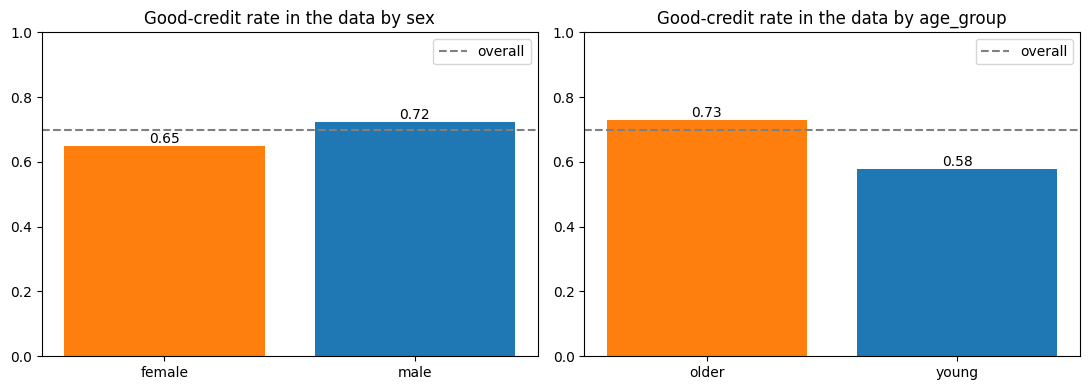

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, attr in zip(axes, PROTECTED):
    rates = df.groupby(attr)["target"].mean()
    bars = ax.bar(rates.index, rates.values, color=["tab:orange", "tab:blue"])
    ax.bar_label(bars, fmt="%.2f")
    ax.axhline(df["target"].mean(), color="grey", linestyle="--", label="overall")
    ax.set_ylim(0, 1); ax.set_title(f"Good-credit rate in the data by {attr}"); ax.legend()
plt.tight_layout(); plt.savefig("base_rates.png", dpi=100); plt.show()

**Interpretation:** The bar charts show the same gaps visually. The orange bar (female, older) and the blue bar (male, young) sit on either side of the grey overall line of 0.70. For age, the young bar (0.58) is far below the older bar (0.73). This historical bias in the labels is the starting point that any model trained on this data has to deal with.

## 3. Train/test split

I use a stratified 70/30 split, so both sets keep the same 70/30 good/bad balance. The original features go into the model exactly as they are (including `personal_status` and `age`), because this is what a "naive" model would do. The two derived columns `sex` and `age_group` are only used to **measure** fairness, not as inputs.

In [6]:
FEATURES = num_cols + cat_cols          # the 20 original attributes

X = df[FEATURES]; 
y = df["target"]; 
groups = df[["sex", "age_group"]]

X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.3, stratify=y, random_state=SPLIT_SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Good-credit rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("Test group sizes:", g_test["sex"].value_counts().to_dict(), g_test["age_group"].value_counts().to_dict())

Train: (700, 20) | Test: (300, 20)
Good-credit rate train/test: 0.7 0.7
Test group sizes: {'male': 209, 'female': 91} {'older': 247, 'young': 53}


**Interpretation:** The training set has 700 rows and the test set 300, and both keep exactly 70% good credit thanks to stratification. The test set contains only 91 women and 53 young applicants. With groups this small, one or two different predictions can move a fairness metric by several points, which is why I add a 20-split robustness check later.

## 4. Baseline logistic regression

In [7]:
def make_pipeline(num, cat):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=2000))])

def fairness_metrics(y_true, y_pred, group, privileged):
    y_true, y_pred, group = np.asarray(y_true), np.asarray(y_pred), np.asarray(group)
    priv, unpriv = group == privileged, group != privileged
    sel = lambda m: y_pred[m].mean()                       # selection (approval) rate
    tpr = lambda m: y_pred[m & (y_true == 1)].mean()       # good borrowers approved
    fpr = lambda m: y_pred[m & (y_true == 0)].mean()       # bad borrowers approved
    return {"SPD": sel(unpriv) - sel(priv),
            "DI": sel(unpriv) / sel(priv),
            "EOD": tpr(unpriv) - tpr(priv),
            "AOD": 0.5 * ((fpr(unpriv) - fpr(priv)) + (tpr(unpriv) - tpr(priv))),
            "sel_priv": sel(priv), "sel_unpriv": sel(unpriv)}

def evaluate(name, y_true, y_pred, y_prob, g):
    row = {"model": name,
           "accuracy": accuracy_score(y_true, y_pred),
           "balanced_acc": balanced_accuracy_score(y_true, y_pred),
           "f1": f1_score(y_true, y_pred),
           "auc": roc_auc_score(y_true, y_prob)}
    for attr, (priv, _) in PROTECTED.items():
        for k, v in fairness_metrics(y_true, y_pred, g[attr], priv).items():
            row[f"{SHORT[attr]}_{k}"] = v
    return row

baseline = make_pipeline(num_cols, cat_cols).fit(X_train, y_train)
prob_base = baseline.predict_proba(X_test)[:, 1]
pred_base = (prob_base >= 0.5).astype(int)

results = [evaluate("Baseline", y_test, pred_base, prob_base, g_test)]
pd.DataFrame(results).set_index("model").T

model,Baseline
accuracy,0.777
balanced_acc,0.685
f1,0.851
auc,0.826
sex_SPD,-0.144
sex_DI,0.830
sex_EOD,-0.099
sex_AOD,-0.109
sex_sel_priv,0.847
sex_sel_unpriv,0.703


**Interpretation:** The baseline model reaches 77.7% accuracy, 0.685 balanced accuracy, an F1-score of 0.851 and an AUC of 0.826, which is a reasonable result for this dataset. On fairness, it approves 84.7% of men but only 70.3% of women: a statistical parity difference of -0.144 and a disparate impact of 0.83, just above the 0.8 line. For age, it approves 81.4% of older and 75.5% of young applicants (disparate impact 0.93). In this particular split the sex gap looks larger than the age gap, but the robustness check below shows that on average the age gap is the bigger problem. The equal opportunity differences (-0.099 for sex, -0.120 for age) mean that good borrowers who are women or young are approved about 10 to 12 points less often than good borrowers who are men or older.

In [8]:
# I look at the confusion matrix per group to see WHERE the errors happen
for attr, (priv, unpriv) in PROTECTED.items():
    for grp in (priv, unpriv):
        m = (g_test[attr] == grp).values
        tn, fp, fn, tp = confusion_matrix(y_test[m], pred_base[m], labels=[0, 1]).ravel()
        print(f"{attr}={grp:6s} n={m.sum():3d} | approved {pred_base[m].mean():.2f} | "
              f"good borrowers approved (TPR) {tp/(tp+fn):.2f} | bad borrowers approved (FPR) {fp/(fp+tn):.2f}")

sex=male   n=209 | approved 0.85 | good borrowers approved (TPR) 0.94 | bad borrowers approved (FPR) 0.59
sex=female n= 91 | approved 0.70 | good borrowers approved (TPR) 0.84 | bad borrowers approved (FPR) 0.47
age_group=older  n=247 | approved 0.81 | good borrowers approved (TPR) 0.93 | bad borrowers approved (FPR) 0.51
age_group=young  n= 53 | approved 0.75 | good borrowers approved (TPR) 0.81 | bad borrowers approved (FPR) 0.67


**Interpretation:** This shows where the unfairness comes from. Good female borrowers are approved 84% of the time, compared with 94% for men, so women are wrongly rejected more often. For age, good young borrowers are approved only 81% of the time, compared with 93% for older applicants. At the same time, bad young borrowers are approved 67% of the time, compared with 51% for older ones. So for young people the model is simply less accurate in both directions: it rejects more good young borrowers and approves more bad ones. This is typical when a group is small (only 53 young people in the test set) and has less training data.

## 5. Fairness interventions

### Intervention 1: Reweighing (pre-processing)

In [9]:
def reweighing_weights(group_labels, y):
    d = pd.DataFrame({"g": np.asarray(group_labels), "y": np.asarray(y)})
    p_g = d["g"].value_counts(normalize=True)
    p_y = d["y"].value_counts(normalize=True)
    p_gy = d.groupby(["g", "y"]).size() / len(d)
    w = d.apply(lambda r: p_g[r.g] * p_y[r.y] / p_gy[(r.g, r.y)], axis=1)
    return w.values, (p_g.to_frame("P(g)").join(p_gy.unstack().rename(columns={0: "P(g,bad)", 1: "P(g,good)"})))

joint_train = (g_train["sex"] + "_" + g_train["age_group"]).values
w_train, rw_table = reweighing_weights(joint_train, y_train)

# I show the weight each group/label combination receives
weights_view = pd.DataFrame({"group": joint_train, "label": y_train.values, "weight": w_train}) \
    .groupby(["group", "label"])["weight"].agg(["first", "size"]).rename(columns={"first": "weight", "size": "rows"})
print(weights_view)

rw_model = make_pipeline(num_cols, cat_cols)
rw_model.fit(X_train, y_train, clf__sample_weight=w_train)
prob_rw = rw_model.predict_proba(X_test)[:, 1]
pred_rw = (prob_rw >= 0.5).astype(int)
results.append(evaluate("Reweighing", y_test, pred_rw, prob_rw, g_test))
pd.DataFrame(results).set_index("model").T

                    weight  rows
group        label              
female_older 0       1.057    42
             1       0.977   106
female_young 0       0.645    33
             1       1.308    38
male_older   0       1.142   109
             1       0.949   306
male_young   0       0.762    26
             1       1.155    40


model,Baseline,Reweighing
accuracy,0.777,0.770
balanced_acc,0.685,0.664
f1,0.851,0.850
auc,0.826,0.815
sex_SPD,-0.144,-0.024
sex_DI,0.830,0.971
sex_EOD,-0.099,0.002
sex_AOD,-0.109,0.015
sex_sel_priv,0.847,0.837
sex_sel_unpriv,0.703,0.813


**Interpretation:** The weights work exactly as intended. "Young + good credit" rows are weighted up (1.31 for young women and 1.16 for young men), because that combination is rarer than it would be if age and outcome were independent. "Young + bad credit" rows are weighted down (0.65 and 0.76). On this split, reweighing almost removes the sex gap: disparate impact goes from 0.83 to 0.97, and the equal opportunity difference goes from -0.099 to 0.002. Accuracy only drops from 0.777 to 0.770. For age, the gap is reversed and slightly over-corrected (disparate impact 1.11, so young applicants are now approved a bit more often than older ones). AUC falls slightly (0.826 to 0.815), so the model ranks applicants a little less well.

### Intervention 2: Disparate Impact Remover (pre-processing)

In [10]:
class DisparateImpactRemover:
    # I learn, for every feature and group, the sorted training values; then map each value to the median distribution
    def __init__(self, repair_level=1.0, n_q=101):
        self.repair_level, self.qs = repair_level, np.linspace(0, 1, n_q)

    def fit(self, X, group):
        group = np.asarray(group)
        self.groups_ = np.unique(group)
        self.sorted_, self.target_q_ = {}, {}
        for col in X.columns:
            self.sorted_[col] = {g: np.sort(X[col].values[group == g]) for g in self.groups_}
            per_group_q = np.vstack([np.quantile(v, self.qs) for v in self.sorted_[col].values()])
            self.target_q_[col] = np.median(per_group_q, axis=0)   # the "median distribution"
        return self

    def transform(self, X, group):
        group = np.asarray(group)
        Xr = X.copy().astype(float)
        for col in X.columns:
            for g in self.groups_:
                m = group == g
                ref = self.sorted_[col][g]
                v = X[col].values[m]
                # I find each value's percentile inside its own group (mid-rank handles ties)
                rank = (np.searchsorted(ref, v, "left") + np.searchsorted(ref, v, "right")) / (2 * len(ref))
                repaired = np.interp(rank, self.qs, self.target_q_[col])
                Xr.loc[m, col] = (1 - self.repair_level) * v + self.repair_level * repaired
        return Xr

repair_cols = [c for c in num_cols if c != "age"]
dir_cat = [c for c in cat_cols if c != "personal_status"]
joint_test = (g_test["sex"] + "_" + g_test["age_group"]).values

dir_ = DisparateImpactRemover(repair_level=1.0).fit(X_train[repair_cols], joint_train)
X_train_dir = pd.concat([dir_.transform(X_train[repair_cols], joint_train), X_train[dir_cat]], axis=1)
X_test_dir = pd.concat([dir_.transform(X_test[repair_cols], joint_test), X_test[dir_cat]], axis=1)



In [11]:
# I check the repair worked: the group medians of a feature should now be almost equal
check = pd.DataFrame({"median_before": X_train["credit_amount"].groupby(joint_train).median(),
                      "median_after": X_train_dir["credit_amount"].groupby(joint_train).median(),
                      "mean_before": X_train["credit_amount"].groupby(joint_train).mean(),
                      "mean_after": X_train_dir["credit_amount"].groupby(joint_train).mean()})
print("Credit amount by group, before vs after repair:\n", check.round(0))

dir_model = make_pipeline(repair_cols, dir_cat).fit(X_train_dir, y_train)
prob_dir = dir_model.predict_proba(X_test_dir)[:, 1]
pred_dir = (prob_dir >= 0.5).astype(int)
results.append(evaluate("DI Remover", y_test, pred_dir, prob_dir, g_test))
pd.DataFrame(results).set_index("model").T

Credit amount by group, before vs after repair:
               median_before  median_after  mean_before  mean_after
female_older       1844.000      2039.000     2709.000    2851.000
female_young       1943.000      2042.000     2572.000    2852.000
male_older         2522.000      2042.000     3527.000    2852.000
male_young         2140.000      2035.000     3196.000    2851.000


model,Baseline,Reweighing,DI Remover
accuracy,0.777,0.770,0.773
balanced_acc,0.685,0.664,0.676
f1,0.851,0.850,0.850
auc,0.826,0.815,0.817
sex_SPD,-0.144,-0.024,-0.095
sex_DI,0.830,0.971,0.887
sex_EOD,-0.099,0.002,-0.082
sex_AOD,-0.109,0.015,-0.047
sex_sel_priv,0.847,0.837,0.842
sex_sel_unpriv,0.703,0.813,0.747


**Interpretation:** The repair check shows the remover works. Before repair, the average credit amount ranged from 2,572 (young women) to 3,527 (older men). After repair, all four groups have an average of about 2,851, so the model can no longer use loan size as a hidden signal for group membership. The effect on fairness is small, though. For sex, disparate impact improves from 0.83 to 0.89, but for age it stays almost the same (0.93 to 0.91). The reason is that most of the information in this dataset is in the **categorical** features (checking account status, credit history, savings), which this method does not repair. Those features still differ between groups, so they act as proxies for the protected attributes. Accuracy stays almost the same (0.773).

### Intervention 3: Group-specific thresholds (post-processing)

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
oof_prob = cross_val_predict(make_pipeline(num_cols, cat_cols), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def tpr_at(prob, y, thr):
    return (prob[y == 1] >= thr).mean()

# I keep the privileged (older) threshold at 0.5 and find the young threshold whose TPR matches it
age_tr = g_train["age_group"].values
target_tpr = tpr_at(oof_prob[age_tr == "older"], y_train.values[age_tr == "older"], 0.5)
grid = np.arange(0.20, 0.80, 0.005)
young_tprs = np.array([tpr_at(oof_prob[age_tr == "young"], y_train.values[age_tr == "young"], t) for t in grid])
thr_young = grid[np.argmin(np.abs(young_tprs - target_tpr))]
THRESHOLDS = {"older": 0.5, "young": round(float(thr_young), 3)}
print("Target TPR (older, threshold 0.5):", round(target_tpr, 3))
print("Chosen thresholds:", THRESHOLDS)

thr_vec = np.where(g_test["age_group"].values == "young", THRESHOLDS["young"], THRESHOLDS["older"])
pred_thr = (prob_base >= thr_vec).astype(int)
results.append(evaluate("Group thresholds (age)", y_test, pred_thr, prob_base, g_test))
pd.DataFrame(results).set_index("model").T

Target TPR (older, threshold 0.5): 0.886
Chosen thresholds: {'older': 0.5, 'young': 0.35}


model,Baseline,Reweighing,DI Remover,Group thresholds (age)
accuracy,0.777,0.770,0.773,0.787
balanced_acc,0.685,0.664,0.676,0.683
f1,0.851,0.850,0.850,0.861
auc,0.826,0.815,0.817,0.826
sex_SPD,-0.144,-0.024,-0.095,-0.076
sex_DI,0.830,0.971,0.887,0.911
sex_EOD,-0.099,0.002,-0.082,-0.042
sex_AOD,-0.109,0.015,-0.047,-0.036
sex_sel_priv,0.847,0.837,0.842,0.856
sex_sel_unpriv,0.703,0.813,0.747,0.780


**Interpretation:** With the normal 0.5 threshold, the model approves 88.6% of good older borrowers on the training folds. To give good young borrowers the same chance, the threshold for young applicants has to drop to 0.35. On the test set this raises the young approval rate from 75.5% to 92.5%, and the age equal opportunity difference goes from -0.120 to +0.067. Accuracy actually rises slightly (0.777 to 0.787), because many of the extra young people approved are good borrowers. The downside is that the average odds difference for age gets worse (0.185), because more bad young borrowers are also approved. Equal opportunity and equal false positive rates cannot both be fully satisfied here.

## 6. Compare all models

In [13]:
res = pd.DataFrame(results).set_index("model")
perf_cols = ["accuracy", "balanced_acc", "f1", "auc"]
fair_cols = [f"{SHORT[a]}_{m}" for a in PROTECTED for m in ["SPD", "DI", "EOD", "AOD"]]
print("PERFORMANCE"); print(res[perf_cols].round(3))
print("\nFAIRNESS (0 is fair for SPD/EOD/AOD, 1 is fair for DI)"); print(res[fair_cols].round(3))

PERFORMANCE
                        accuracy  balanced_acc    f1   auc
model                                                     
Baseline                   0.777         0.685 0.851 0.826
Reweighing                 0.770         0.664 0.850 0.815
DI Remover                 0.773         0.676 0.850 0.817
Group thresholds (age)     0.787         0.683 0.861 0.826

FAIRNESS (0 is fair for SPD/EOD/AOD, 1 is fair for DI)
                        sex_SPD  sex_DI  sex_EOD  sex_AOD  age_SPD  age_DI  \
model                                                                        
Baseline                 -0.144   0.830   -0.099   -0.109   -0.059   0.927   
Reweighing               -0.024   0.971    0.002    0.015    0.092   1.113   
DI Remover               -0.095   0.887   -0.082   -0.047   -0.071   0.914   
Group thresholds (age)   -0.076   0.911   -0.042   -0.036    0.111   1.136   

                        age_EOD  age_AOD  
model                                     
Baseline               

**Interpretation:** On the main split, every model stays within about 1 percentage point of the baseline accuracy (0.770 to 0.787), and AUC stays between 0.815 and 0.826. The interventions therefore cost very little performance. For sex fairness, reweighing is the clear winner, bringing every metric within ±0.03 of perfect. For age fairness, reweighing and the group thresholds remove the original gap (and slightly over-correct it), while the DI (Disparate Impact) Remover barely changes it. One split is not enough to draw firm conclusions, so the next step checks these results over 20 splits.

### Robustness check over 20 random splits
The test set has only 300 people, including about 57 young people and 93 women, so one split can be noisy. Here I repeat the whole process (baseline plus all three interventions) on 20 different random splits and report the mean and standard deviation. This tells me whether the differences are real or just luck.

In [14]:
def run_all(seed):
    Xtr, Xte, ytr, yte, gtr, gte = train_test_split(X, y, groups, test_size=0.3, stratify=y, random_state=seed)
    jtr = (gtr["sex"] + "_" + gtr["age_group"]).values
    jte = (gte["sex"] + "_" + gte["age_group"]).values
    out = []
    # baseline
    m = make_pipeline(num_cols, cat_cols).fit(Xtr, ytr); pb = m.predict_proba(Xte)[:, 1]
    out.append(evaluate("Baseline", yte, (pb >= .5).astype(int), pb, gte))
    # reweighing
    w, _ = reweighing_weights(jtr, ytr)
    m = make_pipeline(num_cols, cat_cols).fit(Xtr, ytr, clf__sample_weight=w); p = m.predict_proba(Xte)[:, 1]
    out.append(evaluate("Reweighing", yte, (p >= .5).astype(int), p, gte))
    # DI remover
    d = DisparateImpactRemover().fit(Xtr[repair_cols], jtr)
    Xtr_d = pd.concat([d.transform(Xtr[repair_cols], jtr), Xtr[dir_cat]], axis=1)
    Xte_d = pd.concat([d.transform(Xte[repair_cols], jte), Xte[dir_cat]], axis=1)
    m = make_pipeline(repair_cols, dir_cat).fit(Xtr_d, ytr); p = m.predict_proba(Xte_d)[:, 1]
    out.append(evaluate("DI Remover", yte, (p >= .5).astype(int), p, gte))
    # group thresholds
    oof = cross_val_predict(make_pipeline(num_cols, cat_cols), Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
    a = gtr["age_group"].values
    tt = tpr_at(oof[a == "older"], ytr.values[a == "older"], 0.5)
    ty = grid[np.argmin(np.abs([tpr_at(oof[a == "young"], ytr.values[a == "young"], t) - tt for t in grid]))]
    tv = np.where(gte["age_group"].values == "young", ty, 0.5)
    out.append(evaluate("Group thresholds (age)", yte, (pb >= tv).astype(int), pb, gte))
    for r in out: r["seed"] = seed
    return out

robust = pd.DataFrame([r for s in range(20) for r in run_all(s)])
order = ["Baseline", "Reweighing", "DI Remover", "Group thresholds (age)"]
show = ["accuracy", "balanced_acc", "auc", "sex_SPD", "sex_DI", "age_SPD", "age_DI", "age_EOD", "age_AOD"]
summary = robust.groupby("model")[show].agg(["mean", "std"]).loc[order]
summary.round(3)

accuracy       balanced_acc         auc       sex_SPD  \
                           mean   std         mean   std  mean   std    mean   
model                                                                          
Baseline                  0.748 0.017        0.668 0.024 0.781 0.026  -0.100   
Reweighing                0.746 0.020        0.662 0.025 0.777 0.025  -0.029   
DI Remover                0.756 0.020        0.677 0.027 0.783 0.025  -0.081   
Group thresholds (age)    0.750 0.017        0.656 0.021 0.781 0.026  -0.056   

                             sex_DI       age_SPD       age_DI       age_EOD  \
                         std   mean   std    mean   std   mean   std    mean   
model                                                                          
Baseline               0.054  0.876 0.066  -0.132 0.054  0.834 0.067  -0.135   
Reweighing             0.057  0.965 0.074  -0.061 0.056  0.922 0.071  -0.074   
DI Remover             0.049  0.899 0.060  -0.126 0.060  0.840 0.077  -0.123   
Group thresholds (age) 0.058  0.934 0.073   0.021 0.059  1.028 0.076   0.005   

                             age_AOD        
                         std    mean   std  
model                                       
Baseline               0.058  -0.068 0.062  
Reweighing             0.068   0.004 0.062  
DI Remover             0.087  -0.060 0.061  
Group thresholds (age) 0.071   0.086 0.068

**Interpretation:** Averaged over 20 splits, the picture is clearer and a bit different from the single split. For the baseline, the **age** gap is the larger one (mean disparate impact 0.834, statistical parity difference -0.132), while the sex gap is smaller (0.876). Reweighing improves both attributes: sex disparate impact rises to 0.965 and age to 0.922, at a cost of only 0.6 points of balanced accuracy (0.668 to 0.662). The group thresholds make age almost perfectly fair on average (disparate impact 1.028, equal opportunity difference 0.005). They also improve sex fairness (0.934) as a side effect, because young people include many women, but they lower balanced accuracy to 0.656. The DI Remover slightly improves sex (0.899) and even improves balanced accuracy (0.677), but it does not fix age (0.840). The standard deviations of 0.06 to 0.08 for the fairness metrics confirm that a single 300-row test set is noisy.

## 7. Visualisations

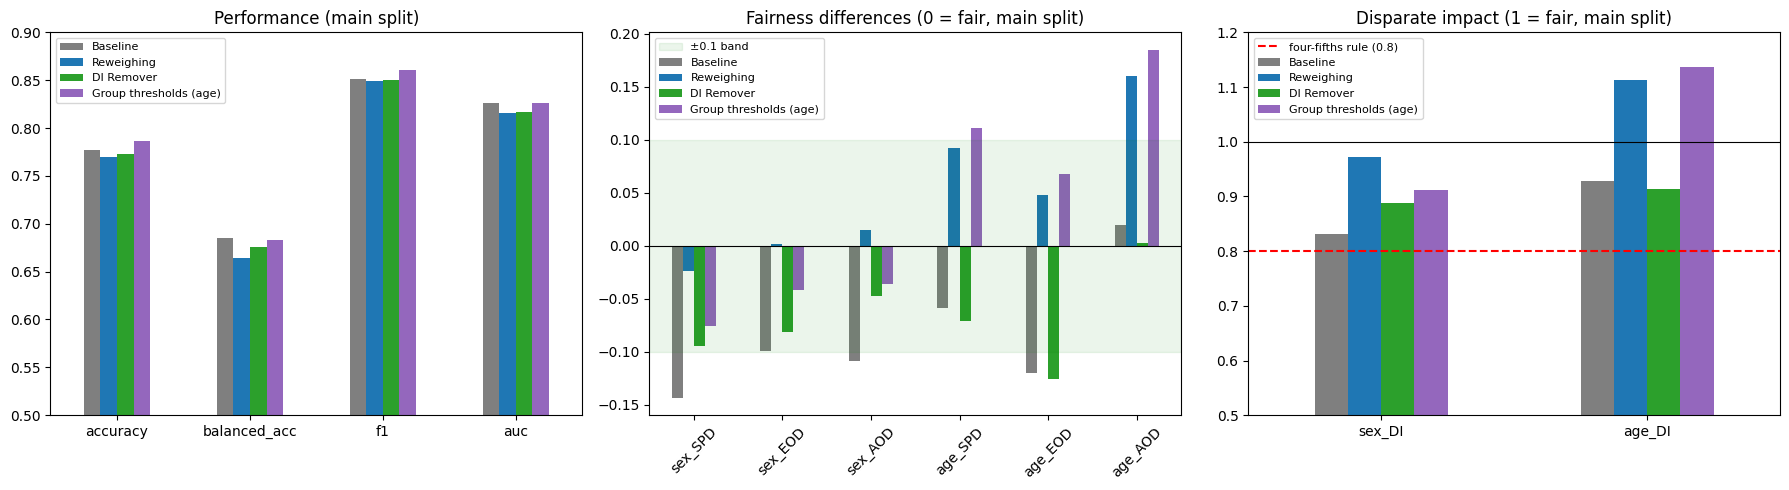

In [15]:
colors = {"Baseline": "tab:grey", "Reweighing": "tab:blue", "DI Remover": "tab:green", "Group thresholds (age)": "tab:purple"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# (a) performance on the main split
res[perf_cols].T.plot(kind="bar", ax=axes[0], color=[colors[m] for m in res.index], rot=0)
axes[0].set_ylim(0.5, 0.9); axes[0].set_title("Performance (main split)"); axes[0].legend(fontsize=8)

# (b) fairness for sex and age on the main split (SPD, EOD, AOD)
fm = res[[f"{SHORT[a]}_{m}" for a in PROTECTED for m in ["SPD", "EOD", "AOD"]]].T
fm.plot(kind="bar", ax=axes[1], color=[colors[m] for m in res.index], rot=45)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].axhspan(-0.1, 0.1, color="green", alpha=0.08, label="±0.1 band")
axes[1].set_title("Fairness differences (0 = fair, main split)"); axes[1].legend(fontsize=8)

# (c) disparate impact ratio with the four-fifths rule
res[["sex_DI", "age_DI"]].T.plot(kind="bar", ax=axes[2], color=[colors[m] for m in res.index], rot=0)
axes[2].axhline(1.0, color="black", lw=0.8); axes[2].axhline(0.8, color="red", ls="--", label="four-fifths rule (0.8)")
axes[2].set_ylim(0.5, 1.2); axes[2].set_title("Disparate impact (1 = fair, main split)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=100); plt.show()

**Interpretation:** The left chart shows that all four models have almost the same accuracy, F1-score and AUC, so the bars are nearly level. The middle chart shows the fairness differences: the grey baseline bars for sex sit outside the green ±0.1 band, while the blue reweighing bars are almost at zero. For age, reweighing and group thresholds flip the bars to positive values (slight over-correction), and the green DI Remover bars stay close to the baseline. The right chart shows every model above the red four-fifths line on this split. Reweighing is closest to 1.0 for sex, and the group thresholds go furthest past 1.0 for age.

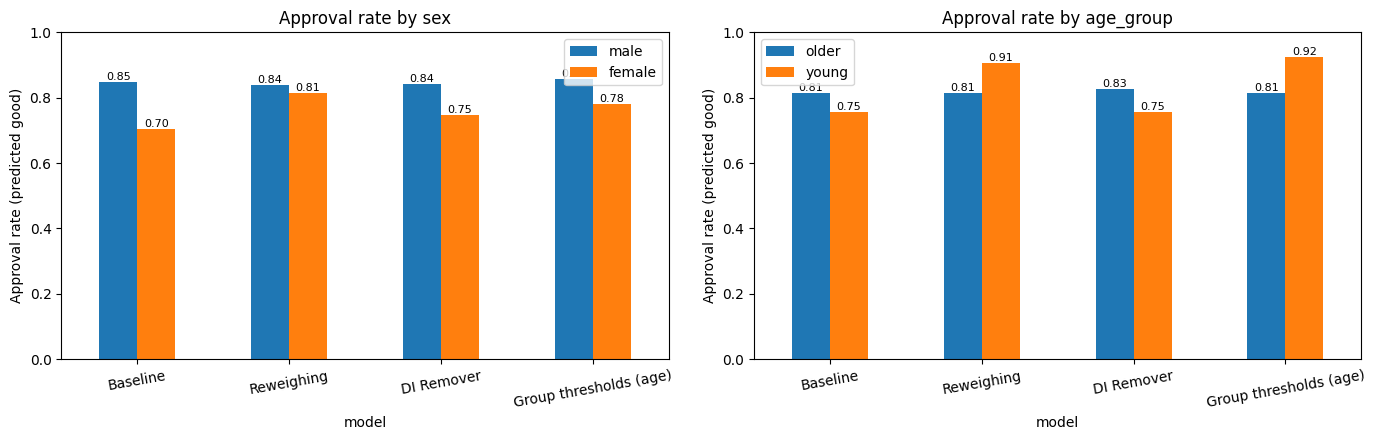

In [16]:
# I compare approval rates for each group, model by model
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (attr, (priv, unpriv)) in zip(axes, PROTECTED.items()):
    sel = res[[f"{SHORT[attr]}_sel_priv", f"{SHORT[attr]}_sel_unpriv"]]
    sel.columns = [priv, unpriv]
    sel.plot(kind="bar", ax=ax, rot=10, color=["tab:blue", "tab:orange"])
    ax.set_ylim(0, 1); ax.set_ylabel("Approval rate (predicted good)")
    ax.set_title(f"Approval rate by {attr}")
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig("approval_rates.png", dpi=100); plt.show()

**Interpretation:** These charts make the decisions easy to understand. In the baseline, men are approved 85% of the time and women 70%. Reweighing closes this gap (84% vs 81%), while the other methods narrow it only partly. For age, the baseline approves 81% of older and 76% of young applicants. Reweighing (91%) and group thresholds (93%) push the young approval rate above the older one, while the DI Remover leaves it unchanged. Approval rates for the privileged groups barely change in any model, so the fairness gains come from approving more people in the disadvantaged groups, not from rejecting more men or older applicants.

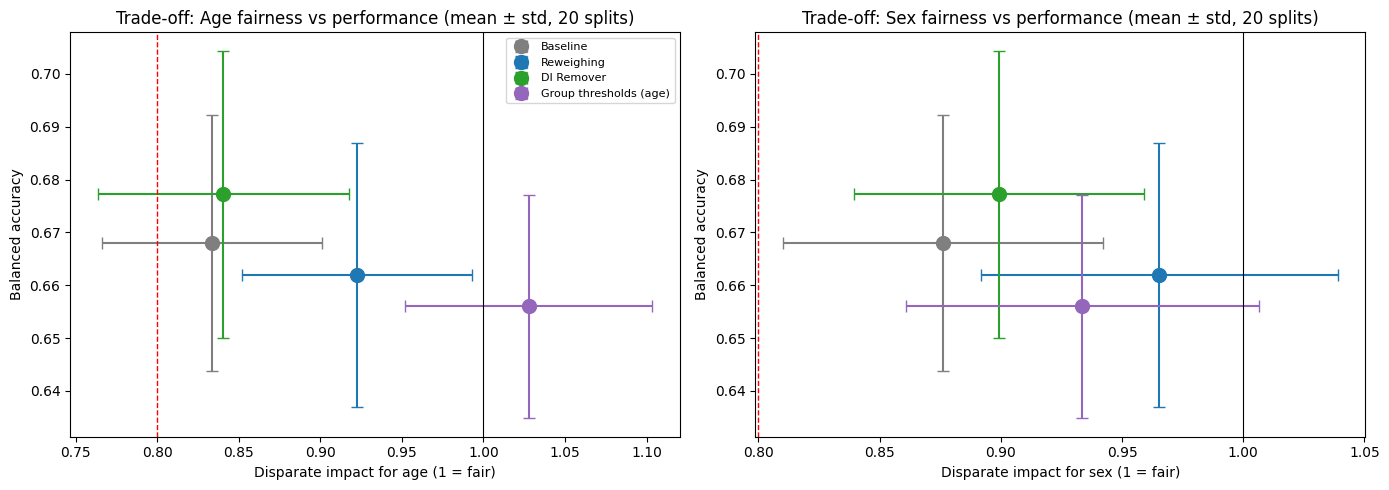

In [17]:
# I plot the fairness-accuracy trade-off averaged over 20 splits, with error bars
means = robust.groupby("model")[["balanced_acc", "age_DI", "sex_DI"]].mean().loc[order]
stds = robust.groupby("model")[["balanced_acc", "age_DI", "sex_DI"]].std().loc[order]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [(axes[0], "age_DI", "Age"), (axes[1], "sex_DI", "Sex")]:
    for mname in order:
        ax.errorbar(means.loc[mname, col], means.loc[mname, "balanced_acc"],
                    xerr=stds.loc[mname, col], yerr=stds.loc[mname, "balanced_acc"],
                    fmt="o", ms=10, capsize=4, color=colors[mname], label=mname)
    ax.axvline(0.8, color="red", ls="--", lw=1); ax.axvline(1.0, color="black", lw=0.8)
    ax.set_xlabel(f"Disparate impact for {title.lower()} (1 = fair)"); ax.set_ylabel("Balanced accuracy")
    ax.set_title(f"Trade-off: {title} fairness vs performance (mean ± std, 20 splits)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("tradeoff_20_splits.png", dpi=100); plt.show()

**Interpretation:** This is the key trade-off chart. Points further right are fairer, and points higher up perform better. For age (left), the baseline sits near the red 0.8 line, the DI Remover stays at the same fairness but is slightly higher (better performance), reweighing moves clearly to the right for a tiny loss, and group thresholds move furthest right, past 1.0, for the largest loss of about 1.2 points. For sex (right), reweighing is the most right-shifted point. The vertical error bars overlap heavily for all models, so the differences in balanced accuracy are smaller than the split-to-split noise. In other words, the fairness gains are real but the accuracy costs are barely measurable.

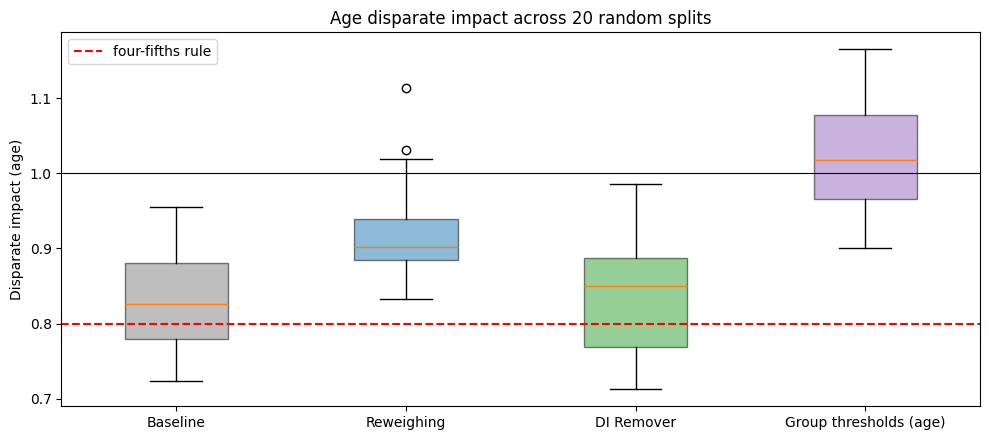

Number of splits (out of 20) with disparate impact below 0.8:
                        age_fail  sex_fail
model                                     
Baseline                       7         2
Reweighing                     0         0
DI Remover                     6         1
Group thresholds (age)         0         0


In [18]:
# I show the spread of the age fairness metric across the 20 splits
fig, ax = plt.subplots(figsize=(10, 4.5))
data = [robust.loc[robust.model == m, "age_DI"].values for m in order]
bp = ax.boxplot(data, tick_labels=order, patch_artist=True)
for patch, m in zip(bp["boxes"], order): patch.set_facecolor(colors[m]); patch.set_alpha(0.5)
ax.axhline(0.8, color="red", ls="--", label="four-fifths rule"); ax.axhline(1.0, color="black", lw=0.8)
ax.set_ylabel("Disparate impact (age)"); ax.set_title("Age disparate impact across 20 random splits"); ax.legend()
plt.tight_layout(); plt.savefig("age_di_boxplot.png", dpi=100); plt.show()

# I count how many of the 20 splits fail the four-fifths rule for each model
fails = robust.assign(age_fail=robust.age_DI < 0.8, sex_fail=robust.sex_DI < 0.8).groupby("model")[["age_fail", "sex_fail"]].sum().loc[order]
print("Number of splits (out of 20) with disparate impact below 0.8:"); print(fails)

**Interpretation:** The boxplot shows the full spread across 20 splits. The baseline's box crosses the red four-fifths line, and the count confirms that the baseline fails the rule for age in 7 out of 20 splits (and for sex in 2). The DI Remover still fails for age in 6 splits. Reweighing and group thresholds never fail in any split, for either attribute. Reweighing has the tightest box, so it gives the most consistent results. The group thresholds box is centred just above 1.0, which means it slightly favours young applicants on average.

## 8. Overall conclusion

**Task 1 and 2 (data and protected attributes).** The German Credit data was clean (no missing values or duplicates), and preprocessing only needed decoding, one-hot encoding and scaling. I chose **sex** (derived from `personal_status`) and **age** (25 or younger vs older) as protected attributes, because both are legally protected in credit decisions and both show a gap in the historical labels. Young applicants were labelled good only 57.9% of the time, compared with 72.8% for older applicants.

**Task 4 (baseline).** A plain logistic regression reached 77.7% accuracy and 0.826 AUC, but it copied the bias in the data. Over 20 splits it failed the four-fifths rule for age in 7 splits. It approved good young borrowers and good female borrowers less often than good older or male borrowers.

**Task 5 and 6 (interventions).**
- **Reweighing** gave the best overall balance. It improved fairness for both attributes at once (mean disparate impact 0.965 for sex and 0.922 for age), never failed the four-fifths rule, and cost only about 0.6 points of balanced accuracy. It also does not change any data or decisions at prediction time, which makes it the easiest to explain and defend.
- **Disparate Impact Remover** successfully equalised the numeric features between groups, but it had little effect on fairness. The bias in this dataset mainly lives in the categorical features (account status, credit history, savings), which act as proxies for age and sex and are not repaired by this method.
- **Group-specific thresholds** gave the strongest correction for age, with almost perfect equal opportunity on average (difference 0.005). However, it slightly over-corrected, lowered balanced accuracy the most (about 1.2 points), and increased the false positive gap. It also uses the protected attribute at decision time, which may not be legal in credit lending.

**Recommendation.** For this credit model I would deploy **reweighing**, because it gives the best balance between fairness, performance and legal safety. I would keep monitoring the fairness metrics over time, as in Assignment 7. The main lesson is that removing sensitive columns, or repairing a few numeric features, is not enough when other features act as proxies. Fairness has to be measured, compared across several random splits (one test set of 300 people is too noisy), and treated as a trade-off that the business and legal teams decide together with the data team.
